In [2717]:
#Install packages
import pandas as pd
import numpy as np
import math

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm   # only for the Q-Q plot in the helper below

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.impute import SimpleImputer, KNNImputer

pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)

In [ ]:
#Claude code assisted in building haversine formula "as the crow flies" distance between two lat/long coordinates in km
#Vectorized with numpy so it works on whole DataFrame columns (NaN in -> NaN out) as well as scalars
def haversine(lat1, lon1, lat2, lon2, unit="km"):
    # Earth's radius in kilometers or miles
    R = 6371.0 if unit == "km" else 3958.8

    # Convert decimal degrees to radians
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)

    # Haversine formula
    a = (
        np.sin(dphi / 2) ** 2
        + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2) ** 2
    )
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return R * c


In [2719]:
#Read and split data
df = pd.read_csv('Taxi-cancellation-case.csv',index_col=0)

X = df.drop(columns=['Car_Cancellation'])
y = df['Car_Cancellation']

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    stratify=y,
    random_state=42
)

y_train_cancellation_rate = y_train.sum()/len(y_train)
y_test_cancellation_rate = y_test.sum()/len(y_test)
print(y_train_cancellation_rate)
print(y_test_cancellation_rate)

X_train.shape

0.07425
0.0745


(8000, 17)

#### Question 1: Split data and benchmark cancellation rate
We split the data into a 80/20 train/test split using stratified sampling to ensure there was a representative number of cancellations in both our train and test set. We confirmed this by taking total cancellations divided by observations for both the train and test set. A cancellation rate of 7.4% for both datasets gives us comfort there was no unintentional drift.

---

In [2720]:
#Assess Missingness
missingness_rate = (X_train.isna().sum() / len(X_train))
print(missingness_rate.sort_values(ascending=False))

to_city_id             0.966875
package_id             0.826375
from_city_id           0.627625
to_date                0.418250
to_long                0.206750
to_lat                 0.206750
to_area_id             0.206750
from_area_id           0.001625
from_long              0.001625
from_lat               0.001625
booking_created        0.000000
user_id                0.000000
mobile_site_booking    0.000000
online_booking         0.000000
vehicle_model_id       0.000000
travel_type_id         0.000000
from_date              0.000000
dtype: float64


In [2721]:
#Analytics on the travel type id

print(X_train['travel_type_id'].value_counts())

null_travel_types = X_train.drop(columns='travel_type_id').isna().groupby(X_train['travel_type_id']).sum()
print(null_travel_types)

travel_type_id
2    6346
3    1389
1     265
Name: count, dtype: int64
                user_id  vehicle_model_id  package_id  from_area_id  \
travel_type_id                                                        
1                     0                 0         265            13   
2                     0                 0        6346             0   
3                     0                 0           0             0   

                to_area_id  from_city_id  to_city_id  from_date  to_date  \
travel_type_id                                                             
1                      265            40           0          0       12   
2                        0          3668        6346          0     2828   
3                     1389          1313        1389          0      506   

                online_booking  mobile_site_booking  booking_created  \
travel_type_id                                                         
1                            0                  

#### Question 2: Assess Missingness
travel type has an imapct on null values. The first observarion is only category 3 (hourly rentals) tend to use a package id. Additionally it seems most hourly rentals or long distance do not populate a destination area/city/lat/long. Interestingly it seems most point-to-point bookings only populate an area or lat/long or area data, leaving city id null. It seems the city identification is primarily used for long distance trips as this is the only location variable populated for this grouping.

| Structural Missingness| Real Gap |
|-----------------------|-----------|
|package_id|from_lat|
|to_area_id|from_long|
|to_city_id|to_date|
|to_lat|from_city_id|
|to_long|from_area_id|

---

In [2722]:
y = X_train['to_date'].isna().astype(int)

X = pd.DataFrame({
    'online_booking': X_train['online_booking'],
    'mobile_site_booking': X_train['mobile_site_booking'],
    'to_lat_missing': X_train['to_lat'].isna().astype(int),
    'long_distance_1': (X_train['travel_type_id'] == 1).astype(int),
    'point_to_point_2': (X_train['travel_type_id'] == 2).astype(int),
    'hourly_rental_3': (X_train['travel_type_id'] == 3).astype(int),
    'from_city_id_missing': X_train['from_city_id'].isna().astype(int)

})

usable = X.notna().all(axis=1)
X, y = X[usable], y[usable]

print(len(X), "rides,", X.shape[1], "features")

8000 rides, 7 features


In [2723]:
X_train_slice, X_test_slice, y_train_slice, y_test_slice = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train_slice.shape, X_test_slice.shape)

(6400, 7) (1600, 7)


In [2724]:
# Majority-class basline (score to beat)

print("Share of rides missing to date:", round(y_train_slice.mean(), 3))
print("Majority-class baseline:            ", round(1 - y_train_slice.mean(), 3))

Share of rides missing to date: 0.418
Majority-class baseline:             0.582


In [2725]:
# K-fold cross validation
# KNN Classifier: 11

folds = KFold(n_splits=10, shuffle=True, random_state=42)

for k in [1, 3, 5, 7, 11, 15, 21, 31]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(pipe, X_train_slice, y_train_slice, cv=folds, scoring='accuracy')
    print("k =", k, " CV accuracy:", round(scores.mean(), 3))

k = 1  CV accuracy: 0.747
k = 3  CV accuracy: 0.835
k = 5  CV accuracy: 0.84
k = 7  CV accuracy: 0.841
k = 11  CV accuracy: 0.84
k = 15  CV accuracy: 0.841
k = 21  CV accuracy: 0.841
k = 31  CV accuracy: 0.841


In [2726]:
# Pipeline creation

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11))
knn.fit(X_train_slice, y_train_slice)

pred = knn.predict(X_test_slice)

In [2727]:
print(confusion_matrix(y_test_slice, pred))

[[678 253]
 [ 19 650]]


In [2728]:
print("Baseline (predict 'present' always):", round(1 - y_test_slice.mean(), 3))
print()
print("Accuracy: ", round(accuracy_score(y_test_slice, pred), 3))
print("Precision:", round(precision_score(y_test_slice, pred), 3))
print("Recall:   ", round(recall_score(y_test_slice, pred), 3))

Baseline (predict 'present' always): 0.582

Accuracy:  0.83
Precision: 0.72
Recall:    0.972


### Question 3: Test for MCAR
The classifier beats the baseline (.83 > .582), whether a ride has a to_date or not
is predictable from whether or not from_city_id is missing or not.
to_date is not missing completly at random.

---

In [2729]:
X_train.head(10)

,user_id,vehicle_model_id,package_id,travel_type_id,from_area_id,to_area_id,from_city_id,to_city_id,from_date,to_date,online_booking,mobile_site_booking,booking_created,from_lat,from_long,to_lat,to_long
row#,,,,,,,,,,,,,,,,,
9818,39476,12,NaN,2,1237.0,393.0,15.0,NaN,8/15/2013 3:50,8/15/2013 5:03,0,0,8/14/2013 17:37,12.926450,77.612060,13.199560,77.706880
8710,41644,12,1.0,3,1026.0,NaN,15.0,NaN,11/5/2013 7:40,11/5/2013 10:20,0,0,10/31/2013 9:37,13.104820,77.576310,NaN,NaN
1405,25651,12,NaN,1,392.0,NaN,15.0,41.0,3/8/2013 6:28,3/8/2013 0:00,0,0,3/7/2013 13:42,12.986284,77.735245,NaN,NaN
4779,33804,54,NaN,1,571.0,NaN,1.0,32.0,7/13/2013 6:57,7/13/2013 0:00,1,0,7/8/2013 14:09,12.951850,77.696420,NaN,NaN
7861,30869,12,1.0,3,1017.0,NaN,NaN,NaN,10/5/2013 8:24,10/5/2013 13:52,0,0,10/4/2013 11:01,13.110840,77.600740,NaN,NaN
5948,2961,12,NaN,1,182.0,NaN,15.0,32.0,8/12/2013 10:04,8/12/2013 23:59,1,0,8/11/2013 18:29,12.945740,77.649280,NaN,NaN
1706,23109,12,NaN,2,393.0,1254.0,NaN,NaN,3/24/2013 18:14,3/25/2013 0:00,1,0,3/24/2013 9:26,13.199560,77.706880,12.934048,77.580568
106,21727,85,NaN,2,393.0,793.0,NaN,NaN,1/6/2013 21:36,NaN,0,0,1/6/2013 12:07,13.199560,77.706880,13.022390,77.594920
5114,33243,12,NaN,2,1395.0,363.0,NaN,NaN,7/19/2013 6:57,7/19/2013 8:15,0,0,7/18/2013 21:24,13.005603,77.628214,12.992870,77.716620


In [2730]:
missingness_rate = (X_train.isna().sum() / len(X_train))
print(missingness_rate.sort_values(ascending=False))

to_city_id             0.966875
package_id             0.826375
from_city_id           0.627625
to_date                0.418250
to_long                0.206750
to_lat                 0.206750
to_area_id             0.206750
from_area_id           0.001625
from_long              0.001625
from_lat               0.001625
booking_created        0.000000
user_id                0.000000
mobile_site_booking    0.000000
online_booking         0.000000
vehicle_model_id       0.000000
travel_type_id         0.000000
from_date              0.000000
dtype: float64


In [2731]:
X_train.columns

Index(['user_id', 'vehicle_model_id', 'package_id', 'travel_type_id',
       'from_area_id', 'to_area_id', 'from_city_id', 'to_city_id', 'from_date',
       'to_date', 'online_booking', 'mobile_site_booking', 'booking_created',
       'from_lat', 'from_long', 'to_lat', 'to_long'],
      dtype='str')

In [2732]:
X_train.dtypes

user_id                  int64
vehicle_model_id         int64
package_id             float64
travel_type_id           int64
from_area_id           float64
to_area_id             float64
from_city_id           float64
to_city_id             float64
from_date                  str
to_date                    str
online_booking           int64
mobile_site_booking      int64
booking_created            str
from_lat               float64
from_long              float64
to_lat                 float64
to_long                float64
dtype: object

In [2733]:
X_train.nunique()

user_id                5831
vehicle_model_id         20
package_id                6
travel_type_id            3
from_area_id            495
to_area_id              454
from_city_id              2
to_city_id               61
from_date              6645
to_date                4329
online_booking            2
mobile_site_booking       2
booking_created        7746
from_lat                401
from_long               398
to_lat                  372
to_long                 369
dtype: int64

In [2734]:
eda = X_train.copy()
eda['cancellation'] = y_train

eda['from_date'] = pd.to_datetime(eda['from_date'])
eda['hour'] = eda['from_date'].dt.hour
eda.groupby('hour')['cancellation'].agg(
    cancellations='sum',
    rides='size',
    rate='mean'
).sort_values('rate', ascending=False)

,cancellations,rides,rate
hour,,,
19,56,342,0.163743
18,92,609,0.151067
17,58,490,0.118367
20,18,183,0.098361
7,46,512,0.089844
21,24,273,0.087912
6,46,569,0.080844
23,20,275,0.072727
9,39,550,0.070909


In [2735]:
area_stats = eda.groupby('from_area_id')['cancellation'].agg(
    cancellations='sum',
    rides='size',
    rate='mean'
)

top_areas = (area_stats[area_stats['cancellations'] > 3]
             .sort_values('rate', ascending=False))
top_areas

n = 20
top_n_list = top_areas.head(n).index.tolist()
print(top_n_list)

[176.0, 1005.0, 994.0, 156.0, 1150.0, 1052.0, 515.0, 61.0, 1165.0, 330.0, 1166.0, 1282.0, 1189.0, 1337.0, 1089.0, 832.0, 1086.0, 363.0, 269.0, 1365.0]


In [2736]:
X_train['package_id_missing'] = np.where(X_train['package_id'].isna(),1,0)
X_train['to_date_missing'] = np.where(X_train['to_date'].isna(),1,0)

drop_rows = X_train[X_train['from_area_id'].isna() | X_train['from_lat'].isna() | X_train['from_long'].isna()].index
X_train = X_train.drop(index=drop_rows)
y_train = y_train.drop(index=drop_rows)

#Deal with the dates, used AI to help engineer numeric feautres from datetime data
for c in ['from_date', 'booking_created']:
    X_train[c] = pd.to_datetime(X_train[c])

#Create booking days before trip and rush hour feature
X_train['booking_days_before_trip'] = (X_train['from_date'] - X_train['booking_created']).dt.total_seconds() / 86400
X_train = X_train.drop(columns=['from_date', 'booking_created'])

#Create haversine distance feature
X_train['haversine_km'] = haversine(X_train['from_lat'], X_train['from_long'],
                                    X_train['to_lat'],   X_train['to_long'])

#Create a top 20 pickups field
# X_train['high_cancel_rate_pickup'] = np.where(X_train['from_area_id'].isin(top_n_list),1,0)

#Encone to_area_id as binary
X_train['to_area_id_missing'] = X_train['to_area_id'].isna().astype(int)
X_train = X_train.drop(columns=['to_area_id'])

# Encode to_date as binary
X_train['to_date_missing'] = X_train['to_date'].isna().astype(int)
X_train = X_train.drop(columns=['to_date'])

X_train = pd.get_dummies(X_train, columns=['travel_type_id'],drop_first=True,dtype=int)

X_train = X_train.drop(columns=['user_id','package_id','to_city_id','from_city_id','vehicle_model_id'])

X_train.shape


(7987, 14)

In [2737]:
drop_cols = ['to_lat']
features = [c for c in X_train.columns if c not in drop_cols]
X_train_area = X_train[features]

has_area_destination = X_train['to_lat'].notna() & X_train_area[features].notna().all(axis=1)

X_area = X_train.loc[has_area_destination, features]
y_area = X_train.loc[has_area_destination, 'to_lat']

print(len(X_area), "cars have an area destination with every feature present")
print("Lat range: mean", round(y_area.mean()), " std", round(y_area.std()))

6346 cars have an area destination with every feature present
Lat range: mean 13  std 0


In [2738]:
folds = KFold(n_splits=10, shuffle=True, random_state=42)

for k in [1, 3, 5, 7, 11, 15, 21, 31, 51, 101]:
    pipe = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    scores = cross_val_score(pipe, X_area, y_area, cv=folds,
                             scoring='neg_root_mean_squared_error')
    print("k =", k, " CV RMSE: ", round(-scores.mean(),ndigits=4))

k = 1  CV RMSE:  0.0446
k = 3  CV RMSE:  0.0408
k = 5  CV RMSE:  0.0413
k = 7  CV RMSE:  0.043
k = 11  CV RMSE:  0.0453
k = 15  CV RMSE:  0.0468
k = 21  CV RMSE:  0.0484
k = 31  CV RMSE:  0.0504
k = 51  CV RMSE:  0.0532
k = 101  CV RMSE:  0.0582


In [2739]:
X_train.dtypes

from_area_id                float64
online_booking                int64
mobile_site_booking           int64
from_lat                    float64
from_long                   float64
to_lat                      float64
to_long                     float64
package_id_missing            int64
to_date_missing               int64
booking_days_before_trip    float64
haversine_km                float64
to_area_id_missing            int64
travel_type_id_2              int64
travel_type_id_3              int64
dtype: object

In [2740]:
prep = make_pipeline(StandardScaler(), KNNImputer(n_neighbors=3))
prep.fit(X_train)

Z_train = pd.DataFrame(prep.transform(X_train), columns=X_train.columns, index=X_train.index)
# Z_test = pd.DataFrame(prep.transform(X_test), columns=X.columns, index=X_test.index)

print("Gaps remaining:", int(Z_train.isna().sum().sum()), "train")
      # int(Z_test.isna().sum().sum()), "test")

Gaps remaining: 0 train


In [2741]:
scaler = prep.named_steps['standardscaler']

filled_train = pd.DataFrame(scaler.inverse_transform(Z_train),
                            columns=X_train.columns, index=X_train.index)

check = pd.DataFrame({
    'observed_mean': X_train.mean().round(1),
    'after_imputation': filled_train.mean().round(1),
    'n_missing': X_train.isna().sum(),
})


check.loc[check['n_missing'] > 0]

,observed_mean,after_imputation,n_missing
to_lat,13.0,13.0,1641
to_long,77.6,77.6,1641
haversine_km,17.3,17.2,1641


In [2742]:
# Sanity check 2: to_lat
imputed_to_lat = filled_train.loc[X_train['to_lat'].isna(), 'to_lat']

print("Imputed to_lat: ", imputed_to_lat.min(), "to ", imputed_to_lat.max())
print("Observed to_lat: ", X_train['to_lat'].min(), "to ", X_train['to_lat'].max())

# Sanity check 2: to_long
imputed_to_long = filled_train.loc[X_train['to_long'].isna(), 'to_long']

print("Imputed to_long: ", imputed_to_long.min(), "to ", imputed_to_long.max())
print("Observed to_long: ", X_train['to_long'].min(), "to ", X_train['to_long'].max())

# Sanity check 2: haversine_km
imputed_haversine_km = filled_train.loc[X_train['haversine_km'].isna(), 'haversine_km']

print("Imputed haversine_km: ", imputed_haversine_km.min(), "to ", imputed_haversine_km.max())
print("Observed haversine_km: ", X_train['haversine_km'].min(), "to ", X_train['haversine_km'].max())

Imputed to_lat:  12.845653 to  13.201977
Observed to_lat:  12.77663 to  13.366072
Imputed to_long:  77.51361 to  77.73781166666667
Observed to_long:  77.38845 to  77.78642
Imputed haversine_km:  1.4483359658641302 to  39.97699056081284
Observed haversine_km:  0.0 to  53.293472036712316


In [2743]:
missingness_rate = (filled_train.isna().sum() / len(filled_train))
print(missingness_rate.sort_values(ascending=False))

from_area_id                0.0
online_booking              0.0
mobile_site_booking         0.0
from_lat                    0.0
from_long                   0.0
to_lat                      0.0
to_long                     0.0
package_id_missing          0.0
to_date_missing             0.0
booking_days_before_trip    0.0
haversine_km                0.0
to_area_id_missing          0.0
travel_type_id_2            0.0
travel_type_id_3            0.0
dtype: float64


In [2744]:
#Apply same transformations to the test set
X_test['package_id_missing'] = np.where(X_test['package_id'].isna(),1,0)
X_test['to_date_missing'] = np.where(X_test['to_date'].isna(),1,0)

drop_rows = X_test[X_test['from_area_id'].isna() | X_test['from_lat'].isna() | X_test['from_long'].isna()].index
X_test = X_test.drop(index=drop_rows)
y_test = y_test.drop(index=drop_rows)

#Deal with the dates, used AI to help engineer numeric feautres from datetime data
for c in ['from_date', 'booking_created']:
    X_test[c] = pd.to_datetime(X_test[c])

X_test['booking_days_before_trip'] = (X_test['from_date'] - X_test['booking_created']).dt.total_seconds() / 86400
X_test = X_test.drop(columns=['from_date', 'booking_created'])

# Haversine distance, same as train (must be added before the reindex or it would be dropped/zero-filled)
X_test['haversine_km'] = haversine(X_test['from_lat'], X_test['from_long'],
                                   X_test['to_lat'],   X_test['to_long'])

#Top 20 busiset pickups
# X_train['high_cancel_rate_pickup'] = np.where(X_train['from_area_id'].isin(top_n_list),1,0)

#Encone to_area_id as binary
X_test['to_area_id_missing'] = X_test['to_area_id'].isna().astype(int)
X_test = X_test.drop(columns=['to_area_id'])

# Encode to_date as binary
X_test['to_date_missing'] = X_test['to_date'].isna().astype(int)
X_test = X_test.drop(columns=['to_date'])

X_test = pd.get_dummies(X_test, columns=['travel_type_id'],drop_first=True,dtype=int)

X_test = X_test.drop(columns=['user_id','package_id','to_city_id','from_city_id','vehicle_model_id'])

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
X_test.shape

(1998, 14)

In [2745]:
Z_test = pd.DataFrame(prep.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Gaps remaining:", int(Z_test.isna().sum().sum()), "test")

Gaps remaining: 0 test


#### Question 4: Transformation & Imputation
Transorm and impute the data to handle nulls summary.
|Column|Method|
|------|-------|
|to_city_id|Dropped because 97% of data was null, can use lat/long as location indicators|
|package_id|Created a missingness flag to capture signal of structural prescence, dropped original column|
|from_city_id|Dropped because 63% of the data was null, can use lat/long as location indicators|
|to_date|Debated making features out of dates, too much noise so dropped|
|to_long|Imputed using KNNimputer as missing data was <30%|
|to_lat|Imputed using KNNimputer as missing data was <30%|
|to_area_id|Imputed using KNNimputer as missing data was <30%|
|from_area_id|Dropped 13 null rows, correlated with other rows missing lat/long data|
|from_long|Dropped 13 null rows, correlated with other rows missing lat/from_area data|
|from_lat|Dropped 13 null rows, correlated with other rows missing long/from_area data|

---

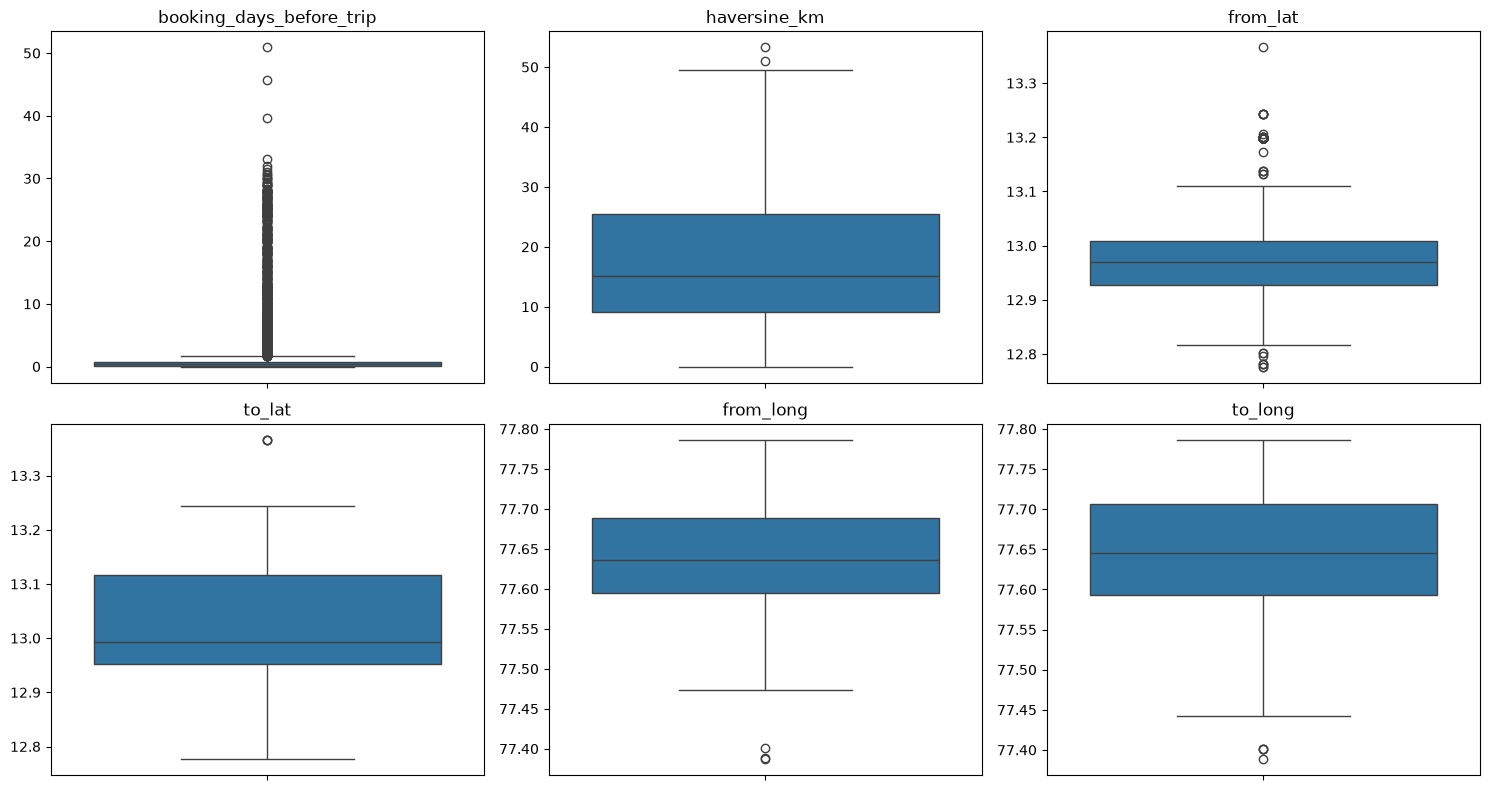

In [2746]:
#Sceen engineered/raw features for outliers, used claude code to help structure the boxplot format
filled_train.columns
screen_columns = ['booking_days_before_trip','haversine_km','from_lat','to_lat','from_long','to_long']
n_cols = 3
n_rows = math.ceil(len(screen_columns)/n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5* n_cols, 4* n_rows))
axes = axes.flatten()

for ax, col in zip(axes,screen_columns):
    sns.boxplot(y=filled_train[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes[len(screen_columns):]:
    ax.set_visible(False)

plt.tight_layout()

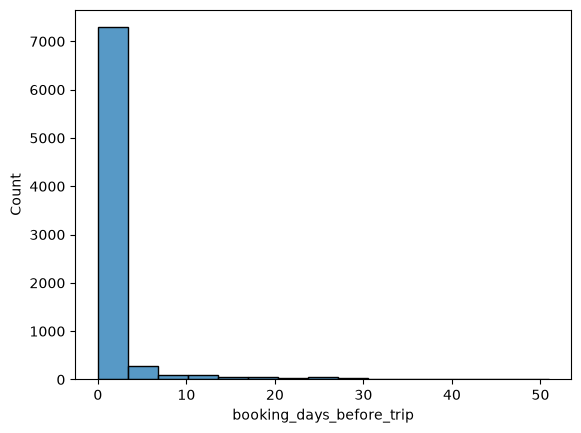

In [2747]:
sns.histplot(filled_train.booking_days_before_trip,bins=15)
plt.show()

#### Question 5: Feature Engineering
We used two engineered features, booking_days_before_trip and haversine_km. The justification for both is as follows.
booking_days_before_trip: The longer the time between booking and trip the higher the liklihood plans change for either party and a cancellation occurs.
haversine_km = this could go either way, for long trips the committment might raise the chance either party cancels, or extremely short trips maybe the consumer decided walking or biking would be a better method of transportation.
We screened for outlier values and while using the IQR method does result in some outliers we decided not to remove these as they represent realistic situations. Taxi rides booked out 50 days in advance, while rare are a service that is provided. Likewise, taxi rides of ~50km would be rare, but also in the realm of possibilities.

---

In [2748]:
corr = filled_train.corr().abs()  # drop .abs() if you want signed ranking

# Used claude code to help identify the top ten the most correlated variables as opposed to trying to view everything on a corr table
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

top_n = (upper.stack()
              .sort_values(ascending=False)
              .head(10))   # change 10 to your n
print(top_n)

package_id_missing  travel_type_id_3      1.000000
to_area_id_missing  travel_type_id_2      1.000000
travel_type_id_2    travel_type_id_3      0.902279
to_area_id_missing  travel_type_id_3      0.902279
package_id_missing  travel_type_id_2      0.902279
                    to_area_id_missing    0.902279
to_lat              haversine_km          0.554023
                    to_long               0.501526
to_long             haversine_km          0.370961
from_lat            haversine_km          0.243524
dtype: float64


In [2749]:
# Correlation of each remaining predictor with the target (training set only)
target_corr = (filled_train
               .corrwith(y_train)
               .rename('corr_with_target')
               .to_frame())
target_corr['abs_corr'] = target_corr['corr_with_target'].abs()
target_corr = target_corr.sort_values('abs_corr', ascending=False)
print(target_corr.round(4))

                          corr_with_target  abs_corr
online_booking                      0.1402    0.1402
haversine_km                       -0.1386    0.1386
to_lat                             -0.1067    0.1067
to_long                            -0.0904    0.0904
from_lat                           -0.0811    0.0811
mobile_site_booking                 0.0589    0.0589
travel_type_id_2                    0.0579    0.0579
to_area_id_missing                 -0.0579    0.0579
to_date_missing                    -0.0501    0.0501
package_id_missing                  0.0470    0.0470
travel_type_id_3                   -0.0470    0.0470
from_long                           0.0453    0.0453
from_area_id                        0.0194    0.0194
booking_days_before_trip            0.0052    0.0052


In [2750]:
#Drop package_id missing as this basically says the same information as travel_type_id. 
#Drop to/from area as this should technically be categorical (codes tell nothing about real distance) and this information is captured within lat/long variables
#Do not remove haversine as distance doesn't capture all the same information ie; highway vs downtown travel differences
filled_train = filled_train.drop(columns=['package_id_missing','from_area_id'])
filled_train.columns

Index(['online_booking', 'mobile_site_booking', 'from_lat', 'from_long',
       'to_lat', 'to_long', 'to_date_missing', 'booking_days_before_trip',
       'haversine_km', 'to_area_id_missing', 'travel_type_id_2',
       'travel_type_id_3'],
      dtype='str')

In [2751]:
#unscale test set and perform same transformations
scaler = prep.named_steps['standardscaler']

filled_test = pd.DataFrame(scaler.inverse_transform(Z_test),
                            columns=X_test.columns, index=X_test.index)

filled_test = filled_test.drop(columns=['package_id_missing','from_area_id'])

In [2752]:
filled_test.columns

Index(['online_booking', 'mobile_site_booking', 'from_lat', 'from_long',
       'to_lat', 'to_long', 'to_date_missing', 'booking_days_before_trip',
       'haversine_km', 'to_area_id_missing', 'travel_type_id_2',
       'travel_type_id_3'],
      dtype='str')

#### Question 6: Check for redundancies
Anaylzed highly correlated predictors and used common knowledge to remove redundancies. Package_missing and travel type id are very highly correlated. Capture the same inforamtion here so removed. While area and lat/long were not correlated (area is a code) we still feel these carry duplicative information. We would have to transform area into categorical data anyway to decided to remove as we are still capturing this signal in Lat/Long data.

---

In [2753]:
folds = KFold(n_splits=10, shuffle=True, random_state=42)

for k in [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(pipe, filled_train, y_train, cv=folds,
                             scoring='recall')
    print("k =", k, " CV recall: ", round(scores.mean(),ndigits=4))

k = 1  CV recall:  0.1987
k = 3  CV recall:  0.1058
k = 5  CV recall:  0.0995
k = 7  CV recall:  0.0576
k = 9  CV recall:  0.0375
k = 11  CV recall:  0.0285
k = 13  CV recall:  0.0251
k = 15  CV recall:  0.0205
k = 17  CV recall:  0.0153
k = 19  CV recall:  0.0121


In [2754]:
for k in [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(pipe, filled_train, y_train, cv=folds,
                             scoring='precision')
    print("k =", k, " CV precision: ", round(scores.mean(),ndigits=4))

k = 1  CV precision:  0.2117
k = 3  CV precision:  0.2704
k = 5  CV precision:  0.3763
k = 7  CV precision:  0.3441
k = 9  CV precision:  0.3376
k = 11  CV precision:  0.4125
k = 13  CV precision:  0.4683
k = 15  CV precision:  0.4652
k = 17  CV precision:  0.5117
k = 19  CV precision:  0.3667


/Users/mattpryor/Documents/Georgetown MSBA/OPAN-6602/Project_2/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


#### Question 7: Evaluate K
We used a KNN 10 fold cross validation and decided to tune the model based on recall. We want to optimze for finding real cancellations to have backup drivers in case of user cancellation. using K of 1 results in the highest recall with multiple neighbors quickly deteriorating the value of our predicitons and tuning the model more towards always predicting no cancellatiom

In [2755]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
knn.fit(filled_train, y_train)

knn_pred = knn.predict(filled_test)

print("KNN recall on the hidden data:", round(recall_score(y_test, knn_pred), 3))

KNN recall on the hidden data: 0.221


In [2756]:
print(confusion_matrix(y_test, knn_pred))

[[1725  124]
 [ 116   33]]


In [2757]:
print("Baseline (predict 'present' always):", round(1 - y_test.mean(), 3))
print("Accuracy: ", round(accuracy_score(y_test, knn_pred), 3))
print("Precision:", round(precision_score(y_test, knn_pred), 3))
print("Recall:   ", round(recall_score(y_test, knn_pred), 3))

Baseline (predict 'present' always): 0.925
Accuracy:  0.88
Precision: 0.21
Recall:    0.221


#### Question 8: Final Model Evaluation
Our model predicted slightly lower than the baseline accuracy of always prediction no cancellation. Since cancellations are such a low probability event, the more neighbors chosen the more likely you are to just select no cancellation accross the board. Given the business context our goal. Our goal is to find what flags a booking as high risk. In doing this we decided to keep low neighbor values and tune towards recall as this is the best indication of finding the real bookings that could cancel. We decided this is more important than precision because if all the business losses is a few minutes over a phone call to confirm a trip then we would rather be overly conservative in estimating cancellations rather than missing real cancellations where we could have intervened.

In [2758]:
simple = SimpleImputer(strategy='most_frequent')
simple.fit(y_train.values.reshape(-1, 1))

# A column of gaps, one per held-out bird, for the imputer to fill.
gaps = np.full((len(y_test), 1), np.nan, dtype=object)
simple_pred = simple.transform(gaps).ravel().astype(y_train.dtype)

print("SimpleImputer fills every gap with:", simple_pred[0])
print()
print("SimpleImputer recall:", round(recall_score(y_test, simple_pred), 3))
print("KNN recall:         ", round(recall_score(y_test, knn_pred), 3))

SimpleImputer fills every gap with: 0

SimpleImputer recall: 0.0
KNN recall:          0.221


In [2759]:
# Attach predictions to the test features
results = filled_test.copy()
results['pred'] = knn_pred

# Split by predicted class
pred1 = results[results['pred'] == 1]
pred0 = results[results['pred'] == 0]

# Compare attribute means between the two groups
cols = filled_test.columns
comp = pd.DataFrame({
    'mean_pred_0': pred0[cols].mean(),
    'mean_pred_1': pred1[cols].mean(),
})
comp['diff'] = comp['mean_pred_1'] - comp['mean_pred_0']

# Scale the difference by overall std so features are comparable
comp['std_diff'] = comp['diff'] / filled_test[cols].std()
comp = comp.reindex(comp['std_diff'].abs().sort_values(ascending=False).index)
print(comp.round(3))

                          mean_pred_0  mean_pred_1   diff  std_diff
online_booking                  0.340        0.631  0.291     0.604
haversine_km                   17.367       13.232 -4.135    -0.421
to_long                        77.642       77.617 -0.024    -0.408
from_lat                       12.983       12.954 -0.029    -0.350
to_lat                         13.031       12.995 -0.036    -0.335
mobile_site_booking             0.039        0.096  0.057     0.281
to_area_id_missing              0.222        0.166 -0.057    -0.137
travel_type_id_2                0.778        0.834  0.057     0.137
from_long                      77.636       77.644  0.008     0.136
to_date_missing                 0.421        0.363 -0.058    -0.117
booking_days_before_trip        1.493        1.170 -0.322    -0.081
travel_type_id_3                0.184        0.153 -0.031    -0.081


#### Question 9:
Our analysis suggestions a few prominent features that could be driving cancellation rates. For one the strongest driver is online bookings. Our model suggests a user who books online is more likely to cancel than one who books through the mobile app or on the phone. Additionally, location also plays a part, interestingly a shorter haversine distance is associated of a higher cancellation rate. Finally the destination coordiates seem to matter as our model predicts higher cancellations southwest of the non-cancellation mean lat/long. As a result we suggest an automated message booking confirmation system that will call or text online customers travelling to these lat/long hotspots. This should alleviate consumer cancellations, as for the driver we suggest running an experiment moving an additional two taxi's to these lat/long hotspots which will be held in reserve for cancellations. We would want to monitor the utiliziation of these drivers to run a cost/benefit analysis on cancellations savings vs lost driver time.


#### Question 10:
A fair amount of our imputation was on destination lat/long. This was an impactful input into our model, while the imputed values remain within the range of observed values they are merely a representation of the data we already had. Destination is just as important as pickup spot and there could be meaningful signal that was missed by imputing rather than having the data on hand. Additionally in our feature engineering we attempted to gather different signals from our data based on plausable reasons for cancellation. Taking haversine_km for example, we calculated this based on lat/long and then imputed this feature, if we had a more complete lat/long field this would impact our metric. In our other feature we did capture some signal from the date fields however given the limited impact of this field in our analysis there is the possibility some signal was left on the table through these fields. The analysis as a whole is limited using KNN to identify a minority class. While we can find some signals on drivers of potential cancellation, actually predicting cancellation with any accuracy was a challenge. The analysis in its current form should be used to inform and as a jump-off point to gathering mroe data. Some useful metrics to prioritize tracking would be complete pickup/destination information. In cancellations, subsetting between if it was customer or driver cancellation, price of the ride for cancellation. Given the limited accuracy of this model we would also want to gather information on the price of circumventive measures taken to prevent each cancellation. If these measures are extremely cheap we would be okay proceeding with a similar model for flagging potential cancellations knowing it will only have a hit rate of 20%, but if the circumventive measures are cheap and we save the business money with each cancellation then this turns into a cost/benefit analysis.